In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/fashionmnist/t10k-labels-idx1-ubyte
/kaggle/input/fashionmnist/t10k-images-idx3-ubyte
/kaggle/input/fashionmnist/fashion-mnist_test.csv
/kaggle/input/fashionmnist/fashion-mnist_train.csv
/kaggle/input/fashionmnist/train-labels-idx1-ubyte
/kaggle/input/fashionmnist/train-images-idx3-ubyte


In [3]:
from sklearn.preprocessing import MinMaxScaler

train = pd.read_csv('/kaggle/input/fashionmnist/fashion-mnist_train.csv')
test = pd.read_csv('/kaggle/input/fashionmnist/fashion-mnist_test.csv')

train_Y = train['label']
train_X = train.drop('label', axis='columns')

test_Y = test['label']
test_X = test.drop('label', axis='columns')

scaler = MinMaxScaler()

train_X = scaler.fit_transform(train_X)
test_X = scaler.transform(test_X)

In [4]:
import tensorflow as tf
class AutoEncoder:
    
    def __init__(self, lr, input_shape):
        self.lr = lr
        
        inputs = tf.keras.Input(shape=input_shape)
        
        x = tf.keras.layers.Dense(784, activation='relu')(inputs)
        x = tf.keras.layers.Dense(500, activation='relu')(x)
        x = tf.keras.layers.Dense(300, activation='relu')(x)
        latent = tf.keras.layers.Dense(200, activation='relu', name='latent')(x)
        
        x = tf.keras.layers.Dense(300, activation='relu')(latent)
        x = tf.keras.layers.Dense(500, activation='relu')(x)
        outputs = tf.keras.layers.Dense(784, activation='relu')(x)
        
        self.model = tf.keras.Model(inputs, outputs)
        
        self.encoder = tf.keras.Model(inputs, latent)
        
        self.model.compile(optimizer='adamw', loss='mse')
        self.model.summary()

    def train(self, x, x_test, epochs, batch_size):
        history = self.model.fit(x, x, batch_size=batch_size, epochs=epochs, validation_data=(x_test, x_test))
        return history

    def predict(self, x):
        return self.model.predict(x)
    
    def encode(self, x):
        return self.encoder.predict(x)

2025-11-13 19:14:04.197872: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1763061244.441153      48 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1763061244.513885      48 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [5]:
lr = 0.01
encoder = AutoEncoder(lr, (784,))

2025-11-13 19:14:27.839956: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 500)            │       392,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 300)            │       150,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 200)            │        60,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │        60,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 500)            │       150,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       392,784 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,822,024 (6.95 MB)

 Trainable params: 1,822,024 (6.95 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
epochs = 10
batch_size = 512
history = encoder.train(train_X, test_X, epochs=epochs, batch_size=batch_size)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - loss: 0.0824 - val_loss: 0.0305
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step - loss: 0.0278 - val_loss: 0.0228
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 8s 70ms/step - loss: 0.0220 - val_loss: 0.0198
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - loss: 0.0192 - val_loss: 0.0177
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - loss: 0.0174 - val_loss: 0.0165
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - loss: 0.0161 - val_loss: 0.0158
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - loss: 0.0156 - val_loss: 0.0156
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 8s 68ms/step - loss: 0.0152 - val_loss: 0.0150
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 8s 68ms/step - loss: 0.0148 - val_loss: 0.0146
Epoch 10/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 8s 68ms/step - loss: 0.0145 - val_loss: 0.0142


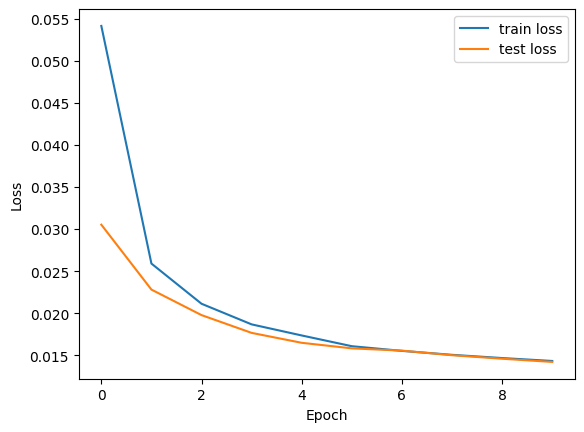

In [7]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='test loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


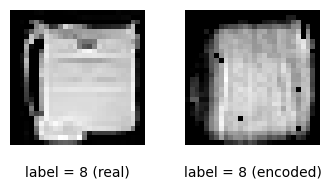

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


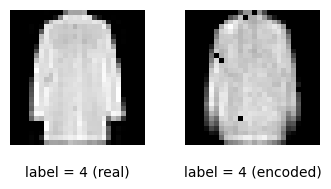

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


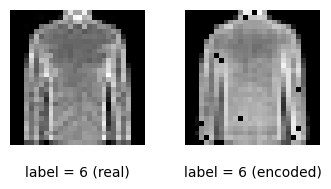

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


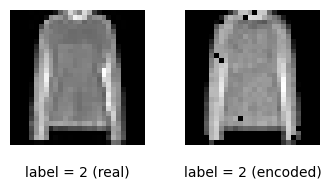

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


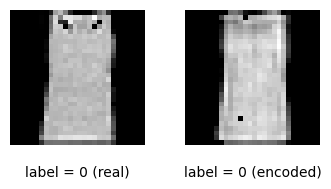

In [16]:
import random
def plot_compare(label, real, pred):
    fig, axes = plt.subplots(1, 2, figsize=(4, 2))

    axes[0].imshow(real, cmap='gray')
    axes[0].axis('off')
    axes[0].text(0.5, -0.15, f"label = {label} (real)", 
                 transform=axes[0].transAxes, 
                 ha='center', va='top', fontsize=10)

    axes[1].imshow(pred, cmap='gray')
    axes[1].axis('off')
    axes[1].text(0.5, -0.15, f"label = {label} (encoded)", 
                 transform=axes[1].transAxes, 
                 ha='center', va='top', fontsize=10)

    plt.subplots_adjust(bottom=0.2, wspace=0.3)  # فضای پایین و بین تصاویر
    plt.show()


labels = [8,4,6,2,0]
for i in labels:
    sample = test[test['label']== i].sample(n=1).drop('label', axis='columns')\
        .values.astype(np.float32)
    pred = encoder.predict(sample)
    img_sample = sample.reshape(28, 28)
    img_pred = pred.reshape(28, 28)
    plot_compare(i, img_sample, img_pred)


In [8]:
test_encoded = encoder.encode(test_X)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [12]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=10, random_state=0, n_init="auto").fit(test_encoded)
cluster_labels = kmeans.labels_

In [19]:
cluster_labels

array([5, 6, 8, ..., 1, 9, 0], dtype=int32)

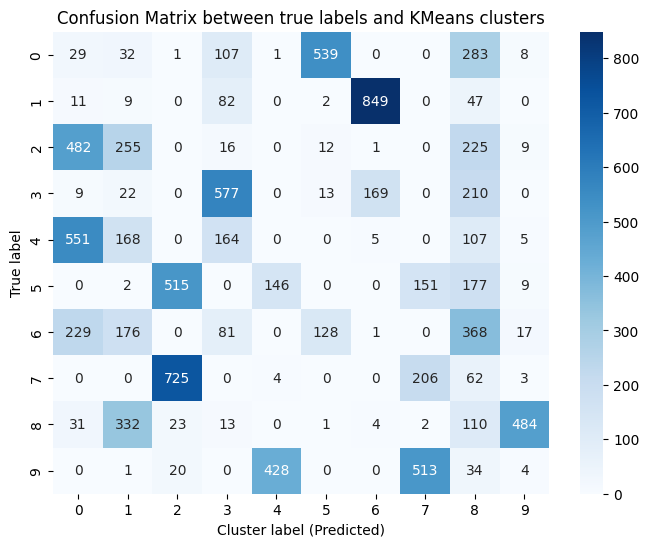

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(test['label'], cluster_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Cluster label (Predicted)")
plt.ylabel("True label")
plt.title("Confusion Matrix between true labels and KMeans clusters")
plt.show()


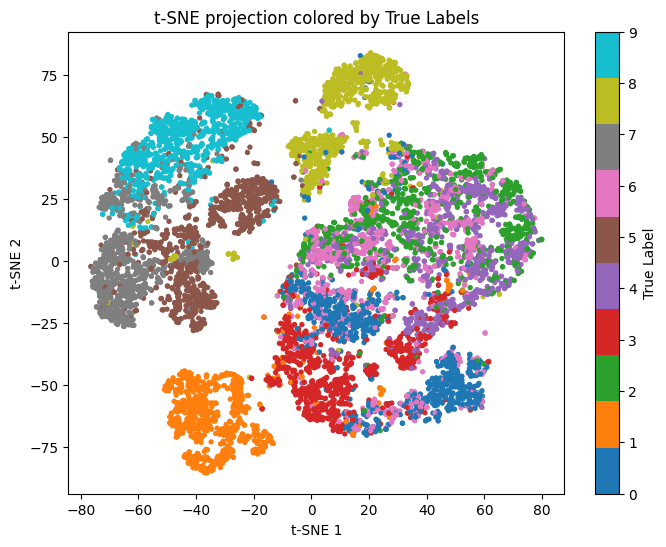

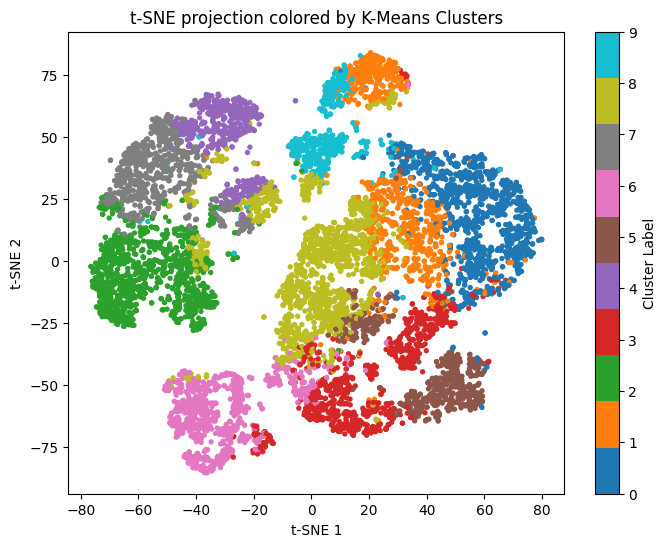

In [21]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
encoded_2d = tsne.fit_transform(test_encoded)

plt.figure(figsize=(8, 6))
plt.scatter(encoded_2d[:, 0], encoded_2d[:, 1], c=test['label'], cmap='tab10', s=8)
plt.title("t-SNE projection colored by True Labels")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(label='True Label')
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(encoded_2d[:, 0], encoded_2d[:, 1], c=cluster_labels, cmap='tab10', s=8)
plt.title("t-SNE projection colored by K-Means Clusters")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(label='Cluster Label')
plt.show()

In [14]:
X_raw = test.drop(columns=['label']).values

kmeans_raw = KMeans(n_clusters=10, random_state=0, n_init="auto").fit(X_raw)
cluster_labels_raw = kmeans_raw.labels_


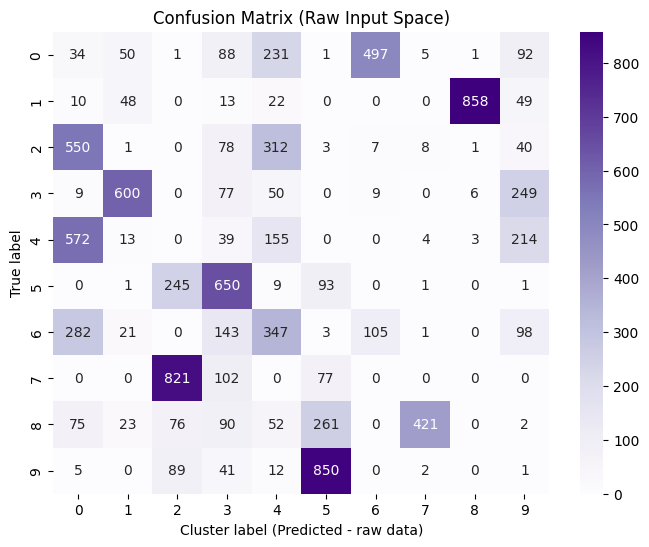

In [23]:
cm_raw = confusion_matrix(test['label'], cluster_labels_raw)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_raw, annot=True, fmt="d", cmap="Purples")
plt.xlabel("Cluster label (Predicted - raw data)")
plt.ylabel("True label")
plt.title("Confusion Matrix (Raw Input Space)")
plt.show()


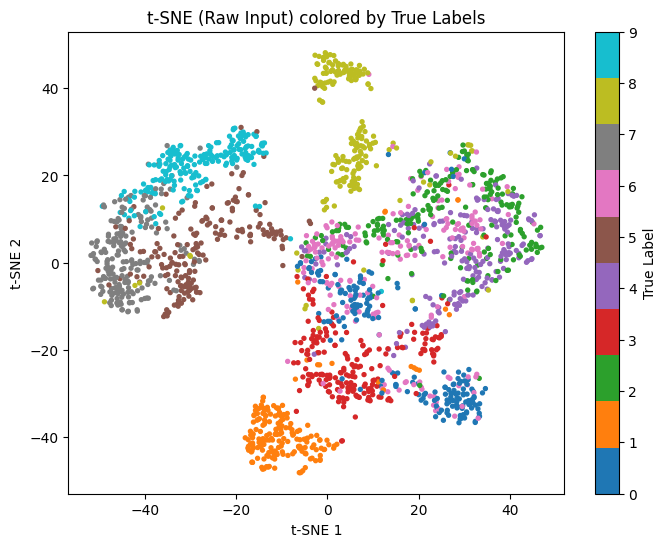

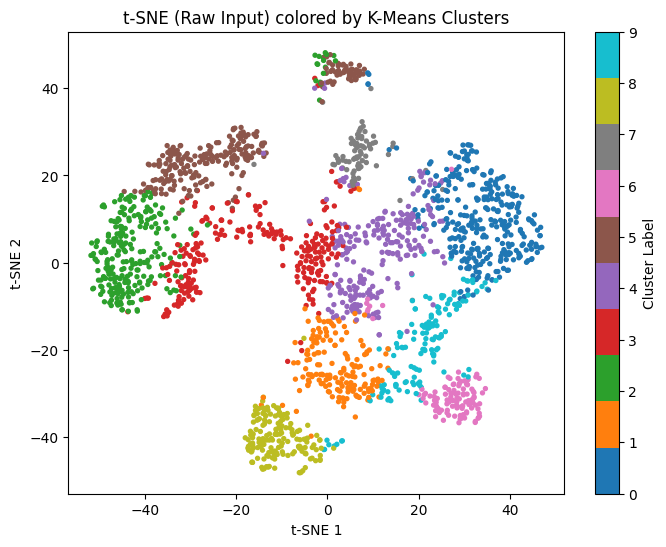

In [24]:
subset = test.sample(n=2000, random_state=42)
X_raw_subset = subset.drop(columns=['label']).values
y_subset = subset['label'].values

tsne_raw = TSNE(n_components=2, random_state=42, perplexity=30)
raw_2d = tsne_raw.fit_transform(X_raw_subset)

plt.figure(figsize=(8, 6))
plt.scatter(raw_2d[:, 0], raw_2d[:, 1], c=y_subset, cmap='tab10', s=8)
plt.title("t-SNE (Raw Input) colored by True Labels")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(label='True Label')
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(raw_2d[:, 0], raw_2d[:, 1], c=kmeans_raw.predict(X_raw_subset), cmap='tab10', s=8)
plt.title("t-SNE (Raw Input) colored by K-Means Clusters")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(label='Cluster Label')
plt.show()

In [10]:
def ARI(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    labels_true = np.unique(y_true)
    labels_pred = np.unique(y_pred)
    n_ij = np.zeros((len(labels_true), len(labels_pred)), dtype=np.int64)

    for i, lt in enumerate(labels_true):
        for j, lp in enumerate(labels_pred):
            n_ij[i, j] = np.sum((y_true == lt) & (y_pred == lp))

    a_i = np.sum(n_ij, axis=1)
    b_j = np.sum(n_ij, axis=0)
    n = np.sum(n_ij)

    def comb2(x): return x * (x - 1) / 2

    sum_comb_c = np.sum(comb2(n_ij))
    sum_comb_a = np.sum(comb2(a_i))
    sum_comb_b = np.sum(comb2(b_j))
    total_comb = comb2(n)

    expected_index = (sum_comb_a * sum_comb_b) / total_comb
    max_index = 0.5 * (sum_comb_a + sum_comb_b)
    ARI_value = (sum_comb_c - expected_index) / (max_index - expected_index)

    return ARI_value


def AMI(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    labels_true = np.unique(y_true)
    labels_pred = np.unique(y_pred)

    n_ij = np.zeros((len(labels_true), len(labels_pred)), dtype=np.int64)
    for i, lt in enumerate(labels_true):
        for j, lp in enumerate(labels_pred):
            n_ij[i, j] = np.sum((y_true == lt) & (y_pred == lp))

    n = np.sum(n_ij)
    p_ij = n_ij / n
    p_i = np.sum(p_ij, axis=1)
    p_j = np.sum(p_ij, axis=0)

    nz = p_ij > 0
    MI = np.sum(p_ij[nz] * np.log(p_ij[nz] / (p_i[:, None] * p_j[None, :])[nz]))

    H_true = -np.sum(p_i[p_i > 0] * np.log(p_i[p_i > 0]))
    H_pred = -np.sum(p_j[p_j > 0] * np.log(p_j[p_j > 0]))

    NMI = MI / ((H_true + H_pred) / 2)

    return NMI




In [15]:
ARI(test['label'], cluster_labels_raw)


0.3804757125830626

In [17]:
ARI(test['label'], cluster_labels)


0.37981651187250426

In [16]:
AMI(test['label'], cluster_labels_raw)

0.5168095879551529

In [18]:
AMI(test['label'], cluster_labels)

0.5444582718134177